# Analysis of the Iris dataset

### Import of packages

In [2]:
# Numerical arrays.
import numpy as np
# Data frames.
import pandas as pd
# Scientific computing.
import scipy
from scipy import stats
# Statistical modeling.
import statsmodels.api as sm
import statsmodels.formula.api as smf
# Download financial market data.
import yfinance as yf
# Plotting.
import matplotlib.pyplot as plt
# Statistical data visualization.
import seaborn as sns
# Machine learning.
import sklearn
# Symbolic mathematics.
import sympy as sp
# Testing.
import pytest


### Import of Iris dataset and data wrangling

Load the iris dataset as a DataFrame with

The `sklearn.datasets` module ([see official documentation](https://scikit-learn.org/stable/api/sklearn.datasets.html)) provides functions for loading example datasets and generating synthetic data.

The `sklearn.datasets.load_iris` function ([see official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)) loads Fisher's iris dataset of 150 flowers from three species, with four measurements per flower.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame


df has the four measurement columns plus a target column holding 0, 1 or 2.
To show species names in place of the numbers, add

In [ ]:
df["species"] = iris.target_names[iris.target]

## Statistical analysis

### Problem 1: Exploring Petal Length
The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.
1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.


#### Problem 1.1: Plot a histogram showing the petal lengths of all 150 flowers.

In [20]:
# Get all the petal length values
counts = df["petal length (cm)"].value_counts()
# Get all unique values of petal length
uniques = df["petal length (cm)"].unique()

The `matplotlib.pyplot` module ([see official documentation](https://matplotlib.org/stable/api/pyplot_summary.html)) provides a state-based interface for creating figures and plots.

The `numpy.arange` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.arange.html)) returns evenly spaced values within a given interval.

The `numpy.floor` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.floor.html)) rounds each element down to the nearest integer.

The `numpy.ceil` function ([see official documentation](https://numpy.org/doc/stable/reference/generated/numpy.ceil.html)) rounds each element up to the nearest integer.

Text(0, 0.5, 'Frequency')

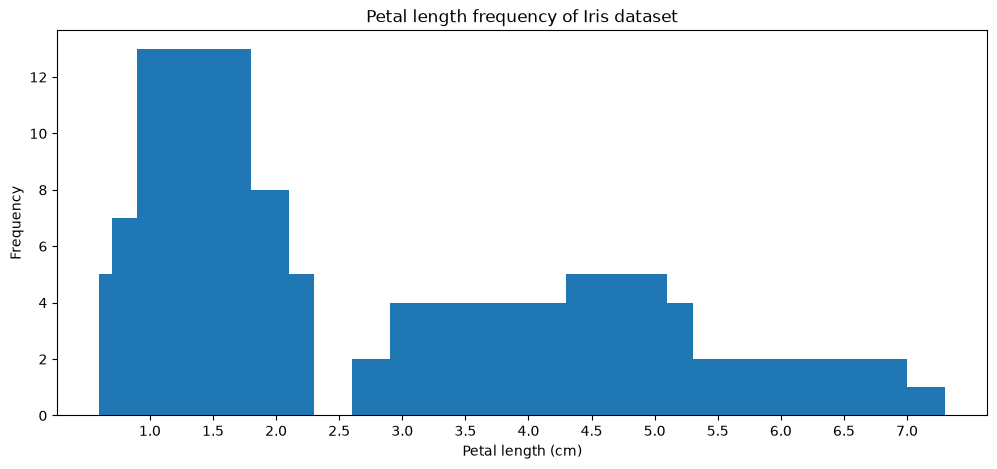

In [ ]:
# Create a blank plot.
fig, ax = plt.subplots(figsize=(12, 5))

# Create a bar chart.
ax.bar(uniques, counts)

# Get the minimum value.
lo = np.floor(np.min(uniques) * 2) / 2
# Get the maximum value.
hi = np.ceil(np.max(uniques) * 2) / 2
# Create a list of values for ticks with 0.5 increments.
# Add 0.25 to the max value to ensure that max is included in the list
# which also avoids getting an extra tick from floating-point error.
ticks = np.arange(lo, hi + 0.25, 0.5)
# Set x ticks.
ax.set_xticks(ticks)

# Add title.
ax.set_title(f'Petal length frequency of Iris dataset')

# Add axis label.
ax.set_xlabel('Petal length (cm)')
ax.set_ylabel('Frequency')

The histogram above represents the distribution of all petal lengths of the Iris dataset. This histogram shows if the distribution of all petal lengths follows a normal distribution. It is important to understand if dataset follows a specific distribution which will dictate what statistical method to choose. If the dataset follows a specific distribution, then a parametric statistical test may be used and if it does not follows any specific distribution, then a non-parametric test may be used ([see source](https://blog.minitab.com/en/blog/adventures-in-statistics-2/choosing-between-a-nonparametric-test-and-a-parametric-test)). For example, if a datset follows a normal distribution, then a t-test for two groups or ANOVA for 3 or more groups may be used to examine the difference between the groups.

#### Problem 1.2 On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

The NIST/SEMATECH e-Handbook of Statistical Methods ([see source](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm)) gives the probability density function, properties and common uses of the normal distribution.

Probability density function of normal distribution:
$$
f(x) = \frac{e^{-(x-\mu)^2/(2\sigma^2)}}{\sigma\sqrt{2\pi}}
$$

In [22]:
def f(x, mu=0.0, sigma=1.0):
  # The normalisation constant.
  norm = 1.0 / np.sqrt(2.0 * np.pi * sigma**2)
  
  # f(x)
  return norm * np.exp(-(x - mu)**2 / (2.0 * sigma**2))

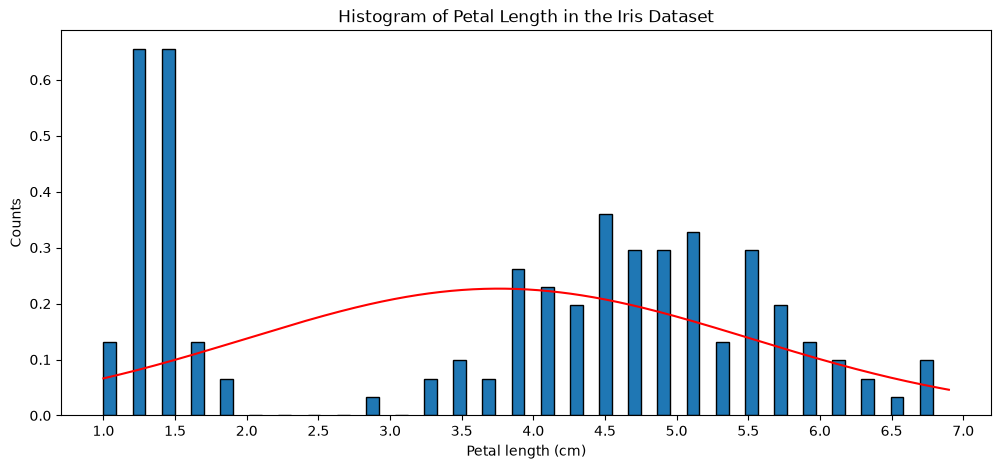

In [50]:
petal_length = df["petal length (cm)"]
mu = np.mean(petal_length)
sigma = np.std(petal_length)

# Create a blank plot.
fig, ax = plt.subplots(figsize=(12, 5))

# Create a histogram.
ax.hist(petal_length, edgecolor='black', 
        bins=np.linspace(petal_length.min(), petal_length.max(), 30), density=True, width=0.09)

# Create an x range.
x = np.linspace(petal_length.min(), petal_length.max(), 1001)
# Get y values.
y = f(x, mu=mu, sigma=sigma)

# Plot the function.
ax.plot(x, y, 'r-')

# Get the minimum value.
lo = np.floor(np.min(uniques) * 2) / 2
# Get the maximum value.
hi = np.ceil(np.max(uniques) * 2) / 2
# Create a list of values for ticks with 0.5 increments.
# Add 0.25 to the max value to ensure that max is included in the list
# which also avoids getting an extra tick from floating-point error.
ticks = np.arange(lo, hi + 0.25, 0.5)
# Set x ticks.
ax.set_xticks(ticks)

# Add title.
ax.set_title(f'Histogram of Petal Length in the Iris Dataset')

# Add axis label.
ax.set_xlabel('Petal length (cm)')
ax.set_ylabel('Counts');


In [31]:
y = f(x, mu=np.mean(counts), sigma=np.std(counts))

np.mean(counts), np.std(counts)

(np.float64(3.488372093023256), np.float64(2.84786409578449))